In [1]:
import sys
from pathlib import Path

package_root = str(Path.cwd().parent)
if package_root not in sys.path:
    sys.path.append(package_root)

In [2]:
from __future__ import annotations
import pandas as pd 
from typing import Dict, List, Tuple
from pathlib import Path
from collections.abc import Iterable
import matplotlib.pyplot as plt
import seaborn as sns
import os 
import time
import re
import numpy as np
from copy import deepcopy
from datetime import datetime
from typing import Any
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
import matplotlib.colors as mcolors

In [3]:
pd.set_option("display.max_colwidth", None)

In [4]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [5]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
MAPPING_LIST_2 = f"{DEVICE_MAPPING_FOLDER}/{DATASET2}/list_of_devices_processed.csv"
INPUT_1 = f"{INPUT_FOLDER}/{DATASET1}"
INPUT_2 = f"{INPUT_FOLDER}/{DATASET2}"

In [6]:
csv_files_1 = [f"{INPUT_1}/{f.name}" for f in sorted(Path(INPUT_1).iterdir()) if f.is_file() and f.suffix == ".csv"]
for file in csv_files_1:
    print(file)

../../../dataset/processed-data/input-data/dataset1/16-09-23.csv
../../../dataset/processed-data/input-data/dataset1/16-09-24.csv
../../../dataset/processed-data/input-data/dataset1/16-09-25.csv
../../../dataset/processed-data/input-data/dataset1/16-09-26.csv
../../../dataset/processed-data/input-data/dataset1/16-09-27.csv
../../../dataset/processed-data/input-data/dataset1/16-09-28.csv
../../../dataset/processed-data/input-data/dataset1/16-09-29.csv
../../../dataset/processed-data/input-data/dataset1/16-09-30.csv
../../../dataset/processed-data/input-data/dataset1/16-10-01.csv
../../../dataset/processed-data/input-data/dataset1/16-10-02.csv
../../../dataset/processed-data/input-data/dataset1/16-10-03.csv
../../../dataset/processed-data/input-data/dataset1/16-10-04.csv
../../../dataset/processed-data/input-data/dataset1/16-10-05.csv
../../../dataset/processed-data/input-data/dataset1/16-10-06.csv
../../../dataset/processed-data/input-data/dataset1/16-10-07.csv
../../../dataset/processe

In [7]:
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)
for mac in device_dict_1:
    print(f"{mac}: {device_dict_1[mac]["device_name"]}")

d0:52:a8:00:67:5e: Smart Things
44:65:0d:56:cc:d3: Amazon Echo
70:ee:50:18:34:43: Netatmo Welcome
f4:f2:6d:93:51:f1: TP-Link Day Night Cloud camera
00:16:6c:ab:6b:88: Samsung SmartCam
30:8c:fb:2f:e4:b2: Dropcam
00:62:6e:51:27:2e: Insteon Camera Wired
e8:ab:fa:19:de:4f: Insteon Camera Wireless
00:24:e4:11:18:a8: Withings Smart Baby Monitor
ec:1a:59:79:f4:89: Belkin Wemo switch
50:c7:bf:00:56:39: TP-Link Smart plug
74:c6:3b:29:d7:1d: iHome
ec:1a:59:83:28:11: Belkin wemo motion sensor
18:b4:30:25:be:e4: NEST Protect smoke alarm
70:ee:50:03:b8:ac: Netatmo weather station
00:24:e4:1b:6f:96: Withings Smart scale
74:6a:89:00:2e:25: Blipcare Blood Pressure meter
00:24:e4:20:28:c6: Withings Aura smart sleep sensor
d0:73:d5:01:83:08: Light Bulbs LiFX Smart Bulb
18:b7:9e:02:20:44: Triby Speaker
e0:76:d0:33:bb:85: PIX-STAR Photo-frame
70:5a:0f:e4:9b:c0: HP Printer
08:21:ef:3b:fc:e3: Samsung Galaxy Tab
30:8c:fb:b6:ea:45: Nest Dropcam
40:f3:08:ff:1e:da: Android Phone
74:2f:68:81:69:42: Laptop
ac:bc:

In [8]:
device_dict_1

{'d0:52:a8:00:67:5e': {'device_name': 'Smart Things',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'hub',
  'vendor': 'Samsung SmartThings'},
 '44:65:0d:56:cc:d3': {'device_name': 'Amazon Echo',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '70:ee:50:18:34:43': {'device_name': 'Netatmo Welcome',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Netatmo'},
 'f4:f2:6d:93:51:f1': {'device_name': 'TP-Link Day Night Cloud camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'TP-Link'},
 '00:16:6c:ab:6b:88': {'device_name': 'Samsung SmartCam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Samsung'},
 '30:8c:fb:2f:e4:b2': {'device_name': 'Dropcam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Dropcam'},
 '00:62:6e:51:27:2e': {'device_name': 'Insteon Camera Wired',
  'ip_address': 

In [9]:
FEATURE_COLUMNS = [
    "packet_count",
    "total_bytes",
]

DEVICE_COLUMN = "eth.src"          # Replace with "eth.src" if applicable
TIME_COLUMN = "timestamp"
LABEL_COLUMN = "is_iot_device"

KPLITS = 5
RANDOM_STATE = 42
WINDOW_SECONDS = 4

In [10]:
# Outgoing volume
def extract_data_from_pcap(
    file_paths: Iterable[str], 
    device_mapping_list: Dict[str, Dict[str,str]]
) -> pd.DataFrame:
    columns = [
        "frame.time_epoch",
        "frame.len",
        "eth.src",
        "eth.dst"
    ]

    all_data = []

    for file_path in file_paths:
        raw_df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category",
                "eth.dst": "category"
            }
        )

        raw_df["capture_id"] = Path(file_path).stem
        all_data.append(raw_df)


    res = pd.concat(all_data, ignore_index=True)
    res = res.sort_values(
        ["frame.time_epoch", "eth.src"],
        ignore_index=True,
    )

    return res


In [11]:
all_data = extract_data_from_pcap(csv_files_1, device_dict_1)

In [31]:
all_data[(all_data["eth.src"] == "b4:75:0e:ec:e5:a9") | (all_data["eth.dst"] == "b4:75:0e:ec:e5:a9")].head(10)

,frame.time_epoch,frame.len,eth.src,eth.dst,capture_id


In [13]:
macs_by_capture = (
    all_data.groupby("capture_id", observed=True)
    .apply(
        lambda df: (
            set(df["eth.src"].dropna())
            | set(df["eth.dst"].dropna())
        )
    )
)

In [14]:
all_macs = set(set.union(*macs_by_capture))

In [15]:
all_macs

{'00:00:00:00:00:00',
 '00:16:6c:ab:6b:88',
 '00:24:e4:10:ee:4c',
 '00:24:e4:11:18:a8',
 '00:24:e4:1b:6f:96',
 '00:24:e4:20:28:c6',
 '00:62:6e:51:27:2e',
 '01:00:5e:00:00:01',
 '01:00:5e:00:00:02',
 '01:00:5e:00:00:16',
 '01:00:5e:00:00:fb',
 '01:00:5e:00:00:fc',
 '01:00:5e:00:01:3c',
 '01:00:5e:02:00:fc',
 '01:00:5e:43:2b:5b',
 '01:00:5e:7f:ff:fa',
 '08:21:ef:3b:fc:e3',
 '14:cc:20:51:33:e9',
 '14:cc:20:51:33:ea',
 '18:b4:30:25:be:e4',
 '18:b7:9e:02:20:44',
 '30:8c:fb:2f:e4:b2',
 '30:8c:fb:b6:ea:45',
 '33:33:00:00:00:01',
 '33:33:00:00:00:02',
 '33:33:00:00:00:0c',
 '33:33:00:00:00:16',
 '33:33:00:00:00:fb',
 '33:33:00:01:00:02',
 '33:33:00:01:00:03',
 '33:33:ff:00:00:00',
 '33:33:ff:00:00:01',
 '33:33:ff:00:0e:e2',
 '33:33:ff:00:0f:8d',
 '33:33:ff:01:37:2f',
 '33:33:ff:01:83:08',
 '33:33:ff:02:75:82',
 '33:33:ff:05:76:b2',
 '33:33:ff:07:7c:19',
 '33:33:ff:15:5b:74',
 '33:33:ff:18:34:43',
 '33:33:ff:22:9d:00',
 '33:33:ff:22:f1:7b',
 '33:33:ff:25:1c:5b',
 '33:33:ff:25:3a:fb',
 '33:33:ff

- I am seeing a lot of weird MAC address, it would not be really useful to visual them all on the graph. Therefore, I will only based off the ground truth list of devices

In [16]:
devices = set(list(device_dict_1.keys()))
device_name_mapping = {mac: device_dict_1[mac]["device_name"] for mac in device_dict_1}

In [17]:
# import matplotlib.colors as mcolors

# # transparent -> opaque blue
# transparent_blue = mcolors.LinearSegmentedColormap.from_list(
#     "transparent_blue",
#     [
#         (0.15, 0.40, 0.85, 0.0),
#         (0.15, 0.40, 0.85, 1.0),
#     ]
# )

# for file_path in csv_files_1:
#     capture_id = Path(file_path).stem

#     curr_data = all_data[all_data["capture_id"] == capture_id].copy()
#     curr_data = curr_data[["eth.src", "eth.dst", "frame.len"]]

#     # only devices present in this capture
#     device_in_capture = sorted(
#         set(curr_data["eth.src"].dropna()) |
#         set(curr_data["eth.dst"].dropna())
#     )
#     device_in_capture = [d for d in device_in_capture if d in devices]

#     adj_matrix = (
#         pd.crosstab(
#             curr_data["eth.src"],
#             curr_data["eth.dst"]
#         )
#         .reindex(
#             index=device_in_capture,
#             columns=device_in_capture,
#             fill_value=0
#         )
#     )

#     # rename labels from MAC -> device name
#     adj_matrix = adj_matrix.rename(
#         index=device_name_mapping,
#         columns=device_name_mapping
#     )

#     values = adj_matrix.values

#     # mask zeros so empty cells remain blank
#     masked_values = np.ma.masked_where(values == 0, values)

#     fig, ax = plt.subplots(figsize=(12, 10))

#     # choose normalization
#     positive_values = values[values > 0]
#     if len(positive_values) > 0:
#         norm = mcolors.LogNorm(
#             vmin=positive_values.min(),
#             vmax=positive_values.max()
#         )
#     else:
#         norm = None

#     im = ax.imshow(
#         masked_values,
#         cmap=transparent_blue,
#         norm=norm,
#         aspect="auto",
#         interpolation="nearest"
#     )

#     cbar = plt.colorbar(im, ax=ax)
#     cbar.set_label("Packet Count")

#     ax.set_xticks(range(len(adj_matrix.columns)))
#     ax.set_xticklabels(adj_matrix.columns, rotation=90, fontsize=7)

#     ax.set_yticks(range(len(adj_matrix.index)))
#     ax.set_yticklabels(adj_matrix.index, fontsize=7)

#     ax.set_xlabel("Destination Device")
#     ax.set_ylabel("Source Device")
#     ax.set_title(f"Device Communication for capture {capture_id}")

#     # annotate cells
#     for i in range(values.shape[0]):
#         for j in range(values.shape[1]):
#             val = values[i, j]

#             # skip zeros to reduce clutter
#             if val == 0:
#                 continue

#             # choose text color for readability
#             if norm is not None:
#                 normalized_val = norm(val)
#             else:
#                 normalized_val = 0 if values.max() == 0 else val / values.max()

#             text_color = "white" if normalized_val > 0.5 else "black"

#             ax.text(
#                 j, i,
#                 str(val),
#                 ha="center",
#                 va="center",
#                 fontsize=6,
#                 color=text_color
#             )

#     plt.tight_layout()
#     plt.show()

In [18]:
# def plot_adjacency_matrix(
#     curr_data,
#     devices,
#     device_name_mapping,
#     metric="packet_count",
#     log_scale=True,
# ):
#     """
#     Plot device-to-device communication as an adjacency matrix.

#     Parameters
#     ----------
#     curr_data : pd.DataFrame
#         Must contain:
#         - eth.src
#         - eth.dst
#         - frame.len

#     devices : set/list
#         MAC addresses of devices to include.

#     device_name_mapping : dict
#         Mapping:
#             MAC address -> device name

#     metric : str
#         "packet_count" or "total_bytes"

#     log_scale : bool
#         Whether to use logarithmic color scaling.
#     """

#     # --------------------------------------------------
#     # Find devices actually appearing in this capture
#     # --------------------------------------------------

#     device_in_capture = sorted(
#         set(curr_data["eth.src"].dropna())
#         | set(curr_data["eth.dst"].dropna())
#     )

#     device_in_capture = [
#         device
#         for device in device_in_capture
#         if device in devices
#     ]

#     # --------------------------------------------------
#     # Construct adjacency matrix
#     # --------------------------------------------------

#     if metric == "packet_count":

#         adj_matrix = pd.crosstab(
#             curr_data["eth.src"],
#             curr_data["eth.dst"]
#         )

#         colorbar_label = "Packet Count"

#     elif metric == "total_bytes":

#         adj_matrix = curr_data.pivot_table(
#             index="eth.src",
#             columns="eth.dst",
#             values="frame.len",
#             aggfunc="sum",
#             fill_value=0,
#             observed=True,
#         )

#         colorbar_label = "Total Bytes"

#     else:
#         raise ValueError(
#             "metric must be 'packet_count' or 'total_bytes'"
#         )

#     # Ensure rows and columns represent same device set
#     adj_matrix = adj_matrix.reindex(
#         index=device_in_capture,
#         columns=device_in_capture,
#         fill_value=0
#     )

#     # MAC -> device name
#     adj_matrix = adj_matrix.rename(
#         index=device_name_mapping,
#         columns=device_name_mapping
#     )

#     # --------------------------------------------------
#     # Plot
#     # --------------------------------------------------

#     values = adj_matrix.to_numpy()

#     masked_values = np.ma.masked_where(
#         values == 0,
#         values
#     )

#     transparent_blue = mcolors.LinearSegmentedColormap.from_list(
#         "transparent_blue",
#         [
#             (0.15, 0.40, 0.85, 0.0),
#             (0.15, 0.40, 0.85, 1.0),
#         ]
#     )

#     fig, ax = plt.subplots(figsize=(12, 10))

#     positive_values = values[values > 0]

#     if log_scale and len(positive_values) > 0:

#         norm = mcolors.LogNorm(
#             vmin=positive_values.min(),
#             vmax=positive_values.max()
#         )

#     else:

#         norm = mcolors.Normalize(
#             vmin=0,
#             vmax=values.max() if values.max() > 0 else 1
#         )

#     im = ax.imshow(
#         masked_values,
#         cmap=transparent_blue,
#         norm=norm,
#         aspect="auto",
#         interpolation="nearest"
#     )

#     # --------------------------------------------------
#     # Axis labels
#     # --------------------------------------------------

#     ax.set_xticks(range(len(adj_matrix.columns)))
#     ax.set_xticklabels(
#         adj_matrix.columns,
#         rotation=90,
#         fontsize=7
#     )

#     ax.set_yticks(range(len(adj_matrix.index)))
#     ax.set_yticklabels(
#         adj_matrix.index,
#         fontsize=7
#     )

#     ax.set_xlabel("Destination Device")
#     ax.set_ylabel("Source Device")

#     ax.set_title(
#         f"Device Communication - {colorbar_label}"
#     )

#     # --------------------------------------------------
#     # Numbers inside cells
#     # --------------------------------------------------

#     for i in range(values.shape[0]):
#         for j in range(values.shape[1]):

#             value = values[i, j]

#             if value == 0:
#                 continue

#             normalized_value = norm(value)

#             text_color = (
#                 "white"
#                 if normalized_value > 0.5
#                 else "black"
#             )

#             # Format differently for bytes
#             if metric == "total_bytes":

#                 if value >= 1_000_000:
#                     label = f"{value / 1_000_000:.1f}M"

#                 elif value >= 1_000:
#                     label = f"{value / 1_000:.1f}K"

#                 else:
#                     label = f"{value:.0f}"

#             else:
#                 label = f"{value:.0f}"

#             ax.text(
#                 j,
#                 i,
#                 label,
#                 ha="center",
#                 va="center",
#                 fontsize=6,
#                 color=text_color
#             )

#     # --------------------------------------------------
#     # Colorbar
#     # --------------------------------------------------

#     cbar = fig.colorbar(im, ax=ax)
#     cbar.set_label(colorbar_label)

#     plt.tight_layout()
#     plt.show()

#     return adj_matrix

In [19]:
# for file_path in csv_files_1:

#     capture_id = Path(file_path).stem

#     curr_data = all_data[
#         all_data["capture_id"] == capture_id
#     ].copy()

#     print(f"Capture: {capture_id}")

#     packet_matrix = plot_adjacency_matrix(
#         curr_data,
#         devices,
#         device_name_mapping,
#         metric="packet_count"
#     )

In [20]:
# for file_path in csv_files_1:

#     capture_id = Path(file_path).stem

#     curr_data = all_data[
#         all_data["capture_id"] == capture_id
#     ].copy()

#     print(f"Capture: {capture_id}")

#     byte_matrix = plot_adjacency_matrix(
#         curr_data,
#         devices,
#         device_name_mapping,
#         metric="total_bytes"
#     )

In [21]:
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D


def plot_adjacency_matrix(
    curr_data,
    device_name_mapping,
    device_dict_1,
    metric="packet_count",
    log_scale=True,
):
    """
    Plot device-to-device communication as an adjacency matrix.

    Row    = source device
    Column = destination device

    Source-device labels indicate whether the device is IoT or non-IoT.
    """

    # --------------------------------------------------
    # Devices to include
    # --------------------------------------------------

    devices = set(device_name_mapping.keys())

    device_in_capture = sorted(
        set(curr_data["eth.src"].dropna())
        | set(curr_data["eth.dst"].dropna())
    )

    device_in_capture = [
        device
        for device in device_in_capture
        if device in devices
    ]

    # --------------------------------------------------
    # Construct adjacency matrix
    # --------------------------------------------------

    if metric == "packet_count":

        adj_matrix = pd.crosstab(
            curr_data["eth.src"],
            curr_data["eth.dst"]
        )

        colorbar_label = "Packet Count"

    elif metric == "total_bytes":

        adj_matrix = curr_data.pivot_table(
            index="eth.src",
            columns="eth.dst",
            values="frame.len",
            aggfunc="sum",
            fill_value=0,
            observed=True,
        )

        colorbar_label = "Total Bytes"

    else:
        raise ValueError(
            "metric must be 'packet_count' or 'total_bytes'"
        )

    adj_matrix = adj_matrix.reindex(
        index=device_in_capture,
        columns=device_in_capture,
        fill_value=0
    )

    # IMPORTANT:
    # Save MAC addresses before replacing them with device names
    source_macs = list(adj_matrix.index)

    # --------------------------------------------------
    # Determine source IoT / non-IoT labels
    # --------------------------------------------------

    source_is_iot = {}

    for mac in source_macs:

        if mac in device_dict_1:
            source_is_iot[mac] = (
                device_dict_1[mac]["is_iot_device"] == 1
            )
        else:
            source_is_iot[mac] = None

    # --------------------------------------------------
    # MAC -> device name
    # --------------------------------------------------

    adj_matrix = adj_matrix.rename(
        index=device_name_mapping,
        columns=device_name_mapping
    )

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------

    values = adj_matrix.to_numpy()

    masked_values = np.ma.masked_where(
        values == 0,
        values
    )

    transparent_blue = mcolors.LinearSegmentedColormap.from_list(
        "transparent_blue",
        [
            (0.15, 0.40, 0.85, 0.0),
            (0.15, 0.40, 0.85, 1.0),
        ]
    )

    fig, ax = plt.subplots(figsize=(12, 10))

    positive_values = values[values > 0]

    if log_scale and len(positive_values) > 0:

        norm = mcolors.LogNorm(
            vmin=positive_values.min(),
            vmax=positive_values.max()
        )

    else:

        norm = mcolors.Normalize(
            vmin=0,
            vmax=values.max() if values.max() > 0 else 1
        )

    im = ax.imshow(
        masked_values,
        cmap=transparent_blue,
        norm=norm,
        aspect="auto",
        interpolation="nearest"
    )

    # --------------------------------------------------
    # X axis: destination device
    # --------------------------------------------------

    ax.set_xticks(range(len(adj_matrix.columns)))

    ax.set_xticklabels(
        adj_matrix.columns,
        rotation=90,
        fontsize=7
    )

    # --------------------------------------------------
    # Y axis: source device + IoT classification
    # --------------------------------------------------

    source_labels = []

    for mac in source_macs:

        device_name = device_name_mapping.get(mac, mac)

        if source_is_iot[mac] is True:
            label = f"{device_name} [IoT]"

        elif source_is_iot[mac] is False:
            label = f"{device_name} [Non-IoT]"

        else:
            label = f"{device_name} [Unknown]"

        source_labels.append(label)

    ax.set_yticks(range(len(source_labels)))

    ax.set_yticklabels(
        source_labels,
        fontsize=7
    )

    # --------------------------------------------------
    # Color source labels based on IoT/non-IoT
    # --------------------------------------------------

    for tick_label, mac in zip(
        ax.get_yticklabels(),
        source_macs
    ):

        if source_is_iot[mac] is True:
            tick_label.set_color("blue")
            tick_label.set_fontweight("bold")

        elif source_is_iot[mac] is False:
            tick_label.set_color("darkorange")
            tick_label.set_fontweight("bold")

        else:
            tick_label.set_color("gray")

    # --------------------------------------------------
    # Axis titles
    # --------------------------------------------------

    ax.set_xlabel("Destination Device")
    ax.set_ylabel("Source Device")

    ax.set_title(
        f"Device Communication - {colorbar_label}"
    )

    # --------------------------------------------------
    # Numbers inside cells
    # --------------------------------------------------

    for i in range(values.shape[0]):

        for j in range(values.shape[1]):

            value = values[i, j]

            if value == 0:
                continue

            normalized_value = norm(value)

            text_color = (
                "white"
                if normalized_value > 0.5
                else "black"
            )

            if metric == "total_bytes":

                if value >= 1_000_000:
                    label = f"{value / 1_000_000:.1f}M"

                elif value >= 1_000:
                    label = f"{value / 1_000:.1f}K"

                else:
                    label = f"{value:.0f}"

            else:
                label = f"{value:.0f}"

            ax.text(
                j,
                i,
                label,
                ha="center",
                va="center",
                fontsize=6,
                color=text_color
            )

    # --------------------------------------------------
    # Colorbar
    # --------------------------------------------------

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(colorbar_label)

    # --------------------------------------------------
    # IoT / Non-IoT legend
    # --------------------------------------------------

    legend_elements = [
        Line2D(
            [0],
            [0],
            color="blue",
            lw=0,
            marker="o",
            label="IoT Source"
        ),
        Line2D(
            [0],
            [0],
            color="darkorange",
            lw=0,
            marker="o",
            label="Non-IoT Source"
        ),
    ]

    ax.legend(
        handles=legend_elements,
        loc="upper left",
        bbox_to_anchor=(1.15, 1)
    )

    plt.tight_layout()
    plt.show()

    return adj_matrix

In [22]:
packet_adj_matrix = (
    pd.crosstab(
        all_data["eth.src"],
        all_data["eth.dst"]
    )
    .reindex(
        index=devices,
        columns=devices,
        fill_value=0
    )
)

packet_adj_matrix = packet_adj_matrix.rename(
    index=device_name_mapping,
    columns=device_name_mapping
)

In [23]:
byte_adj_matrix = (
    all_data
    .pivot_table(
        index="eth.src",
        columns="eth.dst",
        values="frame.len",
        aggfunc="sum",
        fill_value=0,
        observed=True,
    )
    .reindex(
        index=devices,
        columns=devices,
        fill_value=0
    )
)

byte_adj_matrix = byte_adj_matrix.rename(
    index=device_name_mapping,
    columns=device_name_mapping
)

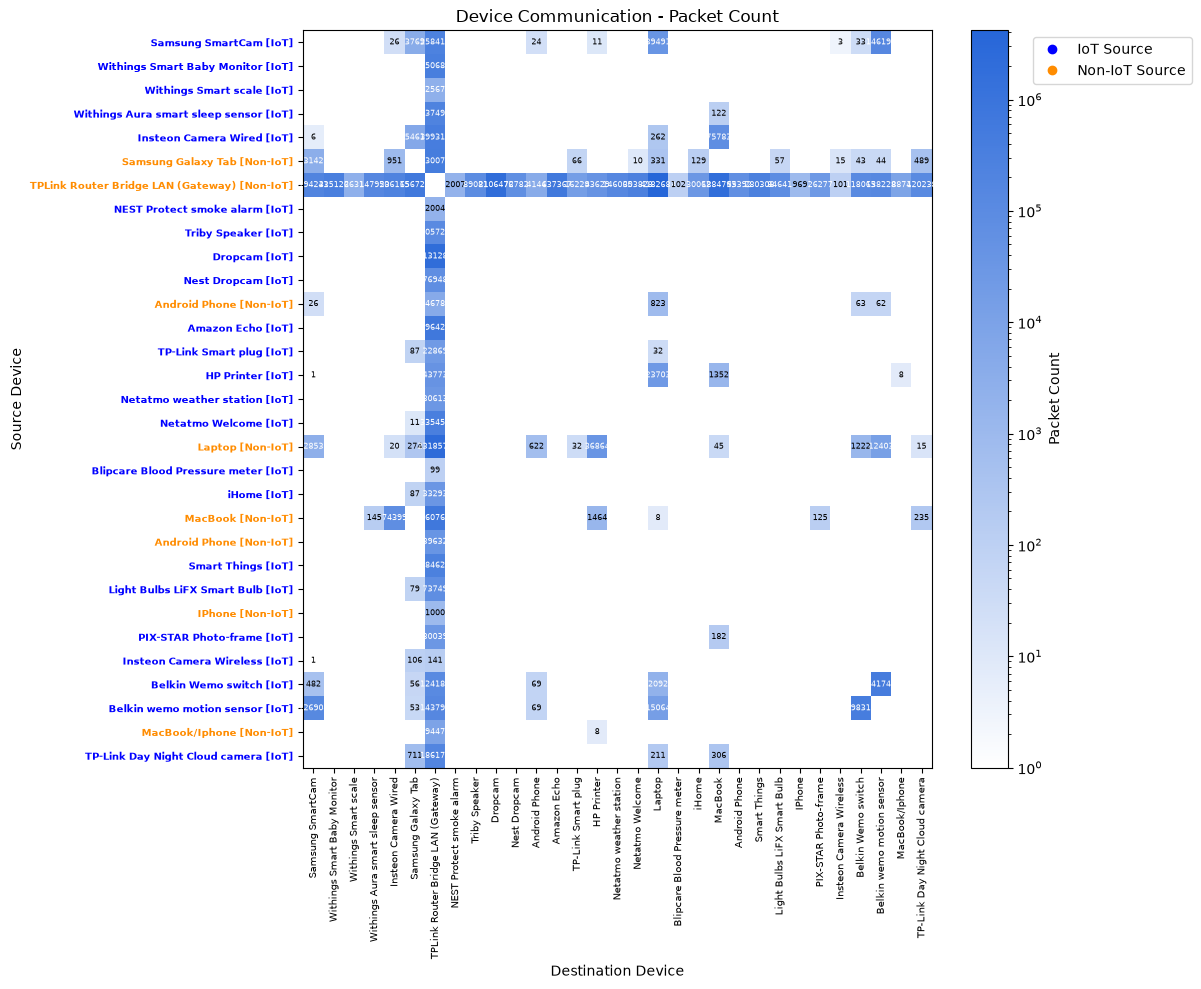

In [24]:
packet_matrix = plot_adjacency_matrix(
    all_data,
    device_name_mapping,
    device_dict_1,
    metric="packet_count"
)

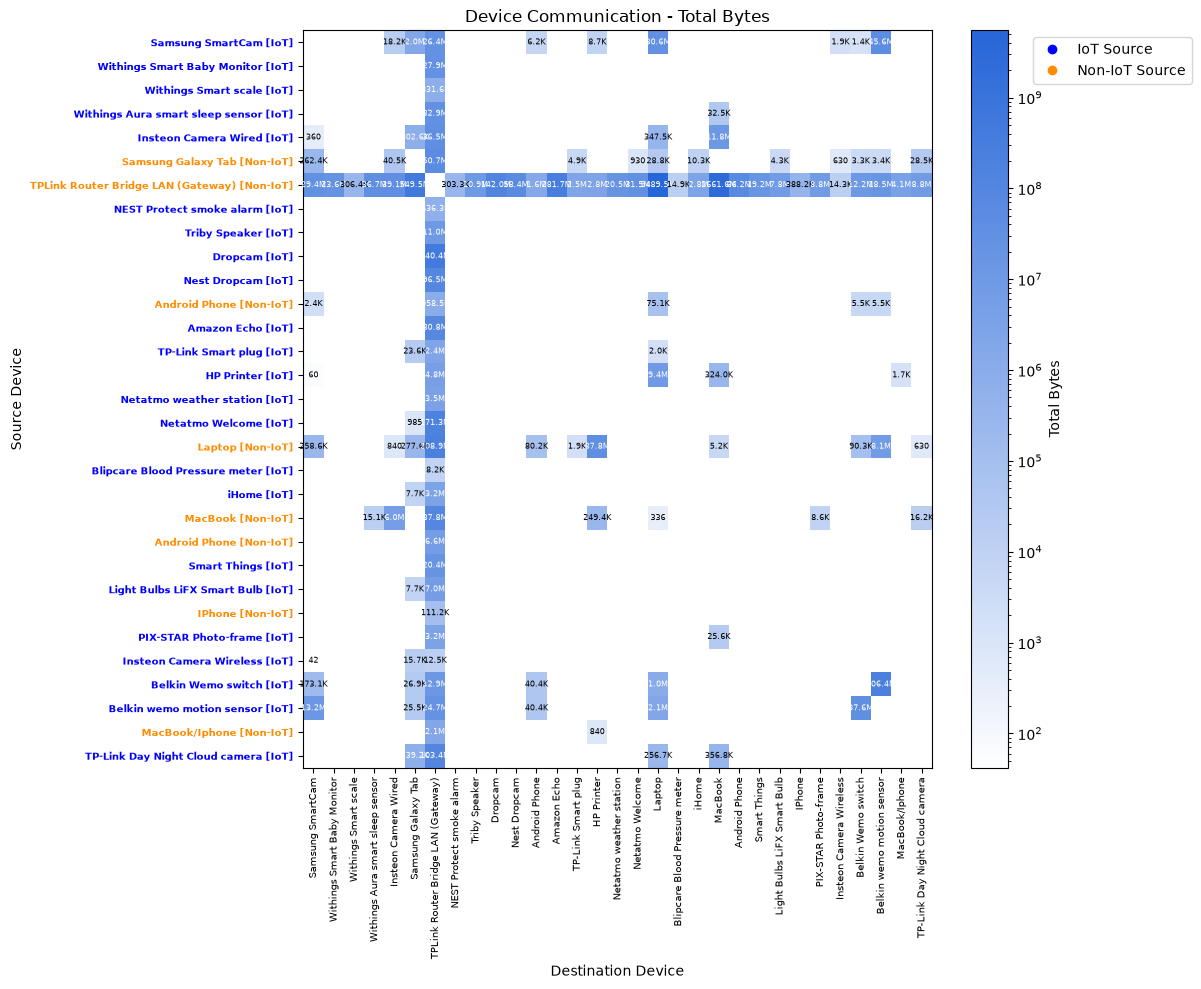

In [25]:
byte_matrix = plot_adjacency_matrix(
    all_data,
    device_name_mapping,
    device_dict_1,
    metric="total_bytes"
)

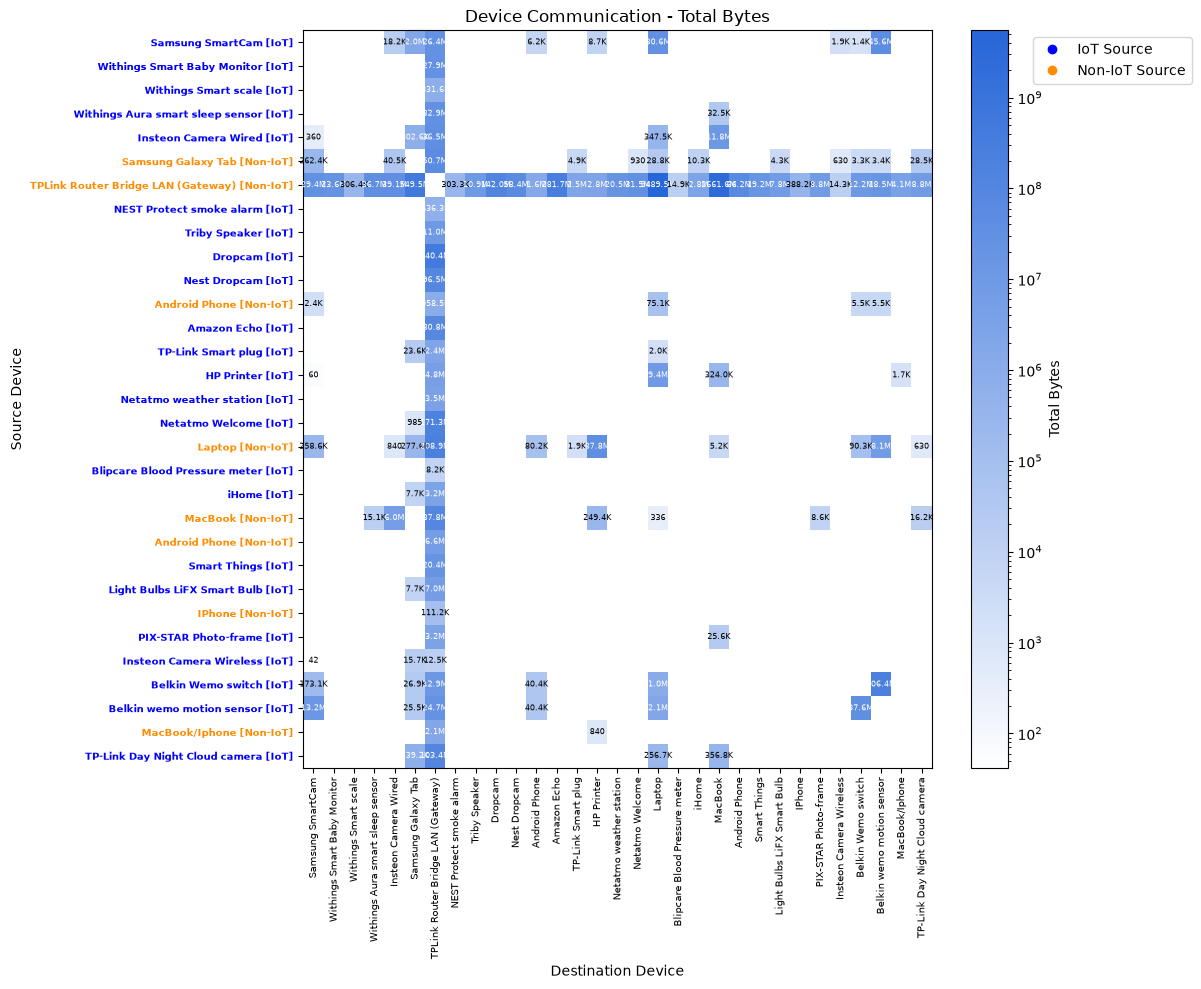

eth.dst,Samsung SmartCam,Withings Smart Baby Monitor,Withings Smart scale,Withings Aura smart sleep sensor,Insteon Camera Wired,Samsung Galaxy Tab,TPLink Router Bridge LAN (Gateway),NEST Protect smoke alarm,Triby Speaker,Dropcam,...,Android Phone,Smart Things,Light Bulbs LiFX Smart Bulb,IPhone,PIX-STAR Photo-frame,Insteon Camera Wireless,Belkin Wemo switch,Belkin wemo motion sensor,MacBook/Iphone,TP-Link Day Night Cloud camera
eth.src,,,,,,,,,,,,,,,,,,,,,
Samsung SmartCam,0,0,0,0,18166,2033853,26359197,0,0,0,...,0,0,0,0,0,1890,1386,45643571,0,0
Withings Smart Baby Monitor,0,0,0,0,0,0,27868705,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Withings Smart scale,0,0,0,0,0,0,831614,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Withings Aura smart sleep sensor,0,0,0,0,0,0,32912083,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Insteon Camera Wired,360,0,0,0,0,802593,36533356,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Samsung Galaxy Tab,262372,0,0,0,40538,0,50686502,0,0,0,...,0,0,4296,0,0,630,3316,3358,0,28471
TPLink Router Bridge LAN (Gateway),29419478,23579209,306361,36706909,39106666,549536943,0,303281,10934707,142028626,...,66194302,19224381,7807758,388169,8822097,14307,12240335,18542187,4053839,8842414
NEST Protect smoke alarm,0,0,0,0,0,0,636313,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Triby Speaker,0,0,0,0,0,0,10982378,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [26]:
plot_adjacency_matrix(
    all_data,
    device_name_mapping,
    device_dict_1,
    metric="total_bytes",
    log_scale=True
)

- Temporal graphs (Dynamic networks): might be useful for event identification?

- Deterministic Rule to identify access point/gateway:
    - Device talking to 99% of the device?
    - What if the gateway would not really talk to every device?

- I just noticed that they have 6 months of data, they only published a subset of it
- Problem: How do a wired device talk to a wireless device?

- Progressively construct rule to identify device type (gateway -> hub -> iot vs non-iot -> ......)
- Device connected to hub usually IoT device
    - If we identify gateway -> hub, very likely we can get IoT device
- More features for the graph?